In [2]:
from pathlib import Path
import pandas as pd

participant = "c1s01"
data_folder = Path("data") / "physiocgm" / "raw" / participant

# Locate the project whether the notebook starts in SleepGuard/
# or SleepGuard/notebooks/.
project = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / data_folder).is_dir()
    ),
    None,
)

if project is None:
    raise FileNotFoundError(
        "Could not find the participant folder. "
        "Run this notebook from inside your SleepGuard project."
    )

recordings = sorted(
    (project / data_folder / "zephyr").rglob("*_ECG.csv")
)

if not recordings:
    raise FileNotFoundError("No ECG recordings found.")

# Preview the first recording; its identity is printed below.
ecg_file = recordings[0]
summary_file = ecg_file.with_name(
    ecg_file.name.removesuffix("_ECG.csv") + "_SummaryEnhanced.csv"
)

print("Participant:", participant)
print("ECG recordings found:", len(recordings))
print("Selected recording:", ecg_file.relative_to(project))

print("\nECG preview:")
print(pd.read_csv(ecg_file, nrows=5).to_string(index=False))

print("\nQuality preview:")
quality_preview = pd.read_csv(
    summary_file,
    nrows=5,
    usecols=["Time", "HR", "HRConfidence", "ECGNoise"],
)
print(quality_preview.to_string(index=False))

Participant: c1s01
ECG recordings found: 29
Selected recording: data/physiocgm/raw/c1s01/zephyr/2022_06_08-13_32_45/Record 3_2022_06_08-13_32_45_ECG.csv

ECG preview:
                   Time  EcgWaveform
08/06/2022 13:32:45.441          179
08/06/2022 13:32:45.445          179
08/06/2022 13:32:45.449          179
08/06/2022 13:32:45.453          179
08/06/2022 13:32:45.457          179

Quality preview:
                   Time  HR  ECGNoise  HRConfidence
08/06/2022 13:32:45.441  65       0.0             0
08/06/2022 13:32:46.441  65       0.0             0
08/06/2022 13:32:47.441  65       0.0             0
08/06/2022 13:32:48.441  65       0.0             0
08/06/2022 13:32:49.441  65       0.0             0


In [3]:
import numpy as np

sampling_rate = 250
date_format = "%d/%m/%Y %H:%M:%S.%f"

session = "2022_06_09-22_02_32"
matches = [path for path in recordings if path.parent.name == session]

if len(matches) != 1:
    raise ValueError(f"Expected one ECG file for {session}, found {len(matches)}.")

ecg_file = matches[0]
summary_file = ecg_file.with_name(
    ecg_file.name.removesuffix("_ECG.csv") + "_SummaryEnhanced.csv"
)

start = pd.Timestamp("2022-06-10 03:41:00")
stop = start + pd.Timedelta(minutes=5)

pieces = []
row_offset = 0

with pd.read_csv(
    ecg_file,
    usecols=["Time", "EcgWaveform"],
    chunksize=250_000,
) as reader:
    for block in reader:
        # Preserve each sample's original position in the recording.
        block["source_sample"] = np.arange(
            row_offset, row_offset + len(block)
        )
        row_offset += len(block)

        block["Time"] = pd.to_datetime(block["Time"], format=date_format)

        if not block["Time"].is_monotonic_increasing:
            raise ValueError("ECG timestamps are out of order.")

        selected = block["Time"].ge(start) & block["Time"].lt(stop)

        if selected.any():
            pieces.append(block.loc[selected].copy())

        if block["Time"].iloc[-1] >= stop:
            break

if not pieces:
    raise ValueError("No ECG samples found in the selected time window.")

segment = pd.concat(pieces, ignore_index=True)

expected_samples = int((stop - start).total_seconds() * sampling_rate)
continuous = (
    segment["Time"].diff().iloc[1:]
    .eq(pd.Timedelta(milliseconds=4))
    .all()
)

if len(segment) != expected_samples or not continuous:
    raise ValueError("This window contains missing or irregular ECG samples.")

if not np.isfinite(segment["EcgWaveform"].to_numpy(dtype=float)).all():
    raise ValueError("This window contains invalid waveform values.")

print("Participant:", participant)
print("Recording:", ecg_file.name)
print("Samples loaded:", len(segment))
print("Time range:", segment["Time"].iloc[0], "to", segment["Time"].iloc[-1])

/var/folders/9l/g984lksj5yx8g8rtrtcf_9_h0000gn/T/ipykernel_55185/302760896.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  stop = start + pd.Timedelta(minutes=5)


Participant: c1s01
Recording: Record 7_2022_06_09-22_02_32_ECG.csv
Samples loaded: 75000
Time range: 2022-06-10 03:41:00.002000 to 2022-06-10 03:45:59.998000


/var/folders/9l/g984lksj5yx8g8rtrtcf_9_h0000gn/T/ipykernel_55185/302760896.py:56: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  .eq(pd.Timedelta(milliseconds=4))


In [5]:
quality = pd.read_csv(
    summary_file,
    usecols=["Time", "HRConfidence", "ECGNoise"],
)

quality["Time"] = pd.to_datetime(quality["Time"], format=date_format)
quality = quality.rename(columns={"Time": "quality_time"})

if not quality["quality_time"].is_monotonic_increasing:
    raise ValueError("Quality timestamps are out of order.")

checked = pd.merge_asof(
    segment,
    quality,
    left_on="Time",
    right_on="quality_time",
    direction="nearest",
    tolerance=pd.Timedelta(seconds=1),
)

hours = checked["Time"].dt.hour

passes = (
    ((hours >= 22) | (hours < 10))
    & checked["HRConfidence"].eq(100)
    & checked["ECGNoise"].lt(0.001)
)

if not passes.all():
    raise ValueError(
        f"{int((~passes).sum())} samples fail the requirements. "
        "Stop here so we can inspect the window."
    )

print("All samples meet the nighttime and quality requirements.")

All samples meet the nighttime and quality requirements.


/var/folders/9l/g984lksj5yx8g8rtrtcf_9_h0000gn/T/ipykernel_55185/846096749.py:18: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  tolerance=pd.Timedelta(seconds=1),


Detected peaks in these five minutes: 287


,participant,recording,source_sample,peak_time,ecg_value,rr_ms
0,c1s01,2022_06_09-22_02_32,5077106,2022-06-10 03:41:00.870,2163,NaN
1,c1s01,2022_06_09-22_02_32,5077375,2022-06-10 03:41:01.946,2142,1076.0
2,c1s01,2022_06_09-22_02_32,5077675,2022-06-10 03:41:03.146,2145,1200.0
3,c1s01,2022_06_09-22_02_32,5077980,2022-06-10 03:41:04.366,2155,1220.0
4,c1s01,2022_06_09-22_02_32,5078264,2022-06-10 03:41:05.502,2165,1136.0
5,c1s01,2022_06_09-22_02_32,5078523,2022-06-10 03:41:06.538,2149,1036.0
6,c1s01,2022_06_09-22_02_32,5078785,2022-06-10 03:41:07.586,2143,1048.0
7,c1s01,2022_06_09-22_02_32,5079056,2022-06-10 03:41:08.670,2152,1084.0
8,c1s01,2022_06_09-22_02_32,5079315,2022-06-10 03:41:09.706,2169,1036.0
9,c1s01,2022_06_09-22_02_32,5079562,2022-06-10 03:41:10.694,2147,988.0


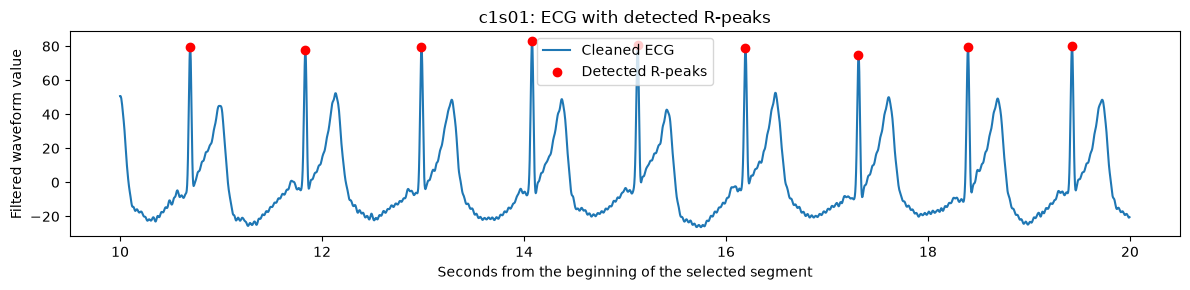

In [6]:
import neurokit2 as nk
import matplotlib.pyplot as plt

waveform = segment["EcgWaveform"].to_numpy(dtype=float)

cleaned = nk.ecg_clean(
    waveform,
    sampling_rate=sampling_rate,
    method="neurokit",
)

_, detection = nk.ecg_peaks(
    cleaned,
    sampling_rate=sampling_rate,
    method="neurokit",
    correct_artifacts=False,
)

locations = detection["ECG_R_Peaks"]

# Convert positions into a readable table: one row per detected beat.
beats = segment.iloc[locations][
    ["source_sample", "Time", "EcgWaveform"]
].reset_index(drop=True)

beats = beats.rename(
    columns={"Time": "peak_time", "EcgWaveform": "ecg_value"}
)
beats.insert(0, "participant", participant)
beats.insert(1, "recording", ecg_file.parent.name)
beats["rr_ms"] = beats["peak_time"].diff().dt.total_seconds() * 1000

print("Detected peaks in these five minutes:", len(beats))
display(beats.head(10))

# Show ten seconds clearly instead of squeezing five minutes onto one plot.
seconds = np.arange(len(cleaned)) / sampling_rate
visible = (seconds >= 10) & (seconds < 20)
shown_peaks = locations[
    (seconds[locations] >= 10) & (seconds[locations] < 20)
]

plt.figure(figsize=(12, 3))
plt.plot(seconds[visible], cleaned[visible], label="Cleaned ECG")
plt.scatter(
    seconds[shown_peaks],
    cleaned[shown_peaks],
    color="red",
    label="Detected R-peaks",
    zorder=3,
)
plt.xlabel("Seconds from the beginning of the selected segment")
plt.ylabel("Filtered waveform value")
plt.title(f"{participant}: ECG with detected R-peaks")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("NeuroKit2:", nk.__version__)

NumPy: 2.5.1
pandas: 2.3.3
NeuroKit2: 0.2.13


In [8]:
output_folder = project / "data" / "physiocgm" / "derived" / participant
output_folder.mkdir(parents=True, exist_ok=True)

output_file = output_folder / "r_peaks_2022-06-10_0341-0346.csv"
beats.to_csv(output_file, index=False)

print("Saved:", output_file)

Saved: /Users/aryan/Documents/GitHub/SleepGuard/data/physiocgm/derived/c1s01/r_peaks_2022-06-10_0341-0346.csv
